# <span style="color:green"> Numerical Simulation Laboratory </span>
## <span style="color:brown"> Python Exercise 12 </span>
## <span style="color:orange"> Keras - Deep & Convolutional Neural Network image recognition </span>

### MNIST with Keras

The goal of exercise 12 is to use deep neural network models, implemented in the Keras python package, to recognize and distinguish between the ten handwritten digits (0-9).

The MNIST dataset comprises $70000$ handwritten digits, each of which comes in a square image, divided into a $28\times 28$ pixel grid. Every pixel can take on $256$ gradation of the gray color, interpolating between white and black, and hence each data point assumes any value in the set $\{0,1,\dots,255\}$. Since there are $10$ categories in the problem, corresponding to the ten digits, this problem represents a generic **classification task**. 

In [15]:
import tensorflow as tf
from tensorflow import keras
import os
import numpy as np
import matplotlib.pyplot as plt
seed=0
np.random.seed(seed) # fix random seed
tf.random.set_seed(seed)

#### Step 1: Load and Process the Data

Keras can conveniently download the MNIST data from the web. All we need to do is import the `mnist` module and use the `load_data()` class, and it will create the training and test data sets or us.

The MNIST set has pre-defined test and training sets, in order to facilitate the comparison of the performance of different models on the data.

Once we have loaded the data, we need to format it in the correct shape.

In [16]:
from keras.datasets import mnist

# input image dimensions
img_rows, img_cols = 28, 28 # number of pixels 
# output
num_classes = 10 # 10 digits

# the data, split between train and test sets
(X_train, Y_train), (X_test, Y_test) = mnist.load_data()

print('X_train shape:', X_train.shape)
print('Y_train shape:', Y_train.shape)

X_train shape: (60000, 28, 28)
Y_train shape: (60000,)


#### Example: to_categorical

Converts a class vector (integers) to binary class matrix. E.g. for use with categorical_crossentropy.

In [17]:
# Consider an array of 5 labels out of a set of 3 classes {0, 1, 2}:
labels = np.array([0, 2, 1, 2, 0])
# `to_categorical` converts this into a matrix with as many columns as there are classes.
# The number of rows stays the same.
keras.utils.to_categorical(labels)

array([[1., 0., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.]])

#### Reshape data and convert labels to be used with categorical cross entropy

X_train shape: (60000, 784)
X_test shape: (10000, 784)

an example of a data point with label 4


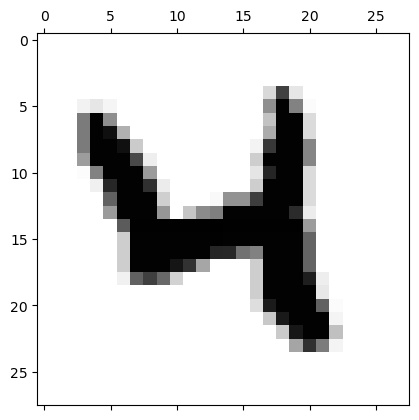

... and with label [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.] after to_categorical

X_train shape: (60000, 784)
Y_train shape: (60000, 10)


In [18]:
# reshape data, it could depend on Keras backend
X_train = X_train.reshape(X_train.shape[0], img_rows*img_cols)
X_test = X_test.reshape(X_test.shape[0], img_rows*img_cols)
print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)
print()

# cast to floats
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

# rescale data in interval [0,1]
X_train /= 255
X_test /= 255

# look at an example of data point
print('an example of a data point with label', Y_train[20])
# matshow: display a matrix in a new figure window
plt.matshow(X_train[20,:].reshape(28,28),cmap='binary')
plt.show()

# convert class vectors to binary class matrices, e.g. for use with categorical_crossentropy
Y_train = keras.utils.to_categorical(Y_train, num_classes)
Y_test = keras.utils.to_categorical(Y_test, num_classes)
print('... and with label', Y_train[20], 'after to_categorical')
print()
print('X_train shape:', X_train.shape)
print('Y_train shape:', Y_train.shape)

#### Step 2: Define the Neural Net and its Architecture

We can now move on to construct our deep neural net. We shall use Keras's `Sequential()` class to instantiate a model, and will add different deep layers one by one using the `add()` method

For the purposes of our example, it suffices to focus on `Dense` layers for simplicity. Every `Dense()` layer accepts as its first required argument an integer which specifies the number of neurons. The type of activation function for the layer is defined using the `activation` optional argument, the input of which is the name of the activation function in `string` format. Examples include `relu`, `tanh`, `elu`, `sigmoid`, `softmax`. 

In order for our DNN to work properly, we have to make sure that the numbers of input and output neurons for each layer match. Therefore, we specify the shape of the input in the first layer of the model explicitly using the optional argument `input_shape=(N_features,)`. The sequential construction of the model then allows Keras to infer the correct input/output dimensions of all hidden layers automatically. Hence, we only need to specify the size of the softmax output layer to match the number of categories.

In [19]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Input

def create_DNN():
    # instantiate model
    model = Sequential()
    model.add(Input(shape=(img_rows*img_cols,)))
    # add a dense all-to-all relu layer
    model.add(Dense(400, activation='relu'))
    # add a dense all-to-all relu layer
    model.add(Dense(100, activation='relu'))
    # apply dropout with rate 0.5
    model.add(Dropout(0.5))
    # soft-max layer
    model.add(Dense(num_classes, activation='softmax'))
    
    return model

print('Model architecture created successfully!')

Model architecture created successfully!


#### Step 3: Choose the Optimizer and the Cost Function

Next, we choose the loss function according to which to train the DNN. For classification problems, this is the cross entropy, and since the output data was cast in categorical form, we choose the `categorical_crossentropy` defined in Keras' `losses` module. Depending on the problem of interest one can pick any other suitable loss function. To optimize the weights of the net, we choose SGD. This algorithm is already available to use under Keras' `optimizers` module, but we could use any other built-in one as well. The parameters for the optimizer, such as `lr` (learning rate) or `momentum` are passed using the corresponding optional arguments of the `SGD()` function. All available arguments can be found in Keras' online documentation at [https://keras.io/](https://keras.io/). While the loss function and the optimizer are essential for the training procedure, to test the performance of the model one may want to look at a particular `metric` of performance. For instance, in categorical tasks one typically looks at their `accuracy`, which is defined as the percentage of correctly classified data points. To complete the definition of our model, we use the `compile()` method, with optional arguments for the `optimizer`, `loss`, and the validation `metric` as follows:

In [20]:
from keras.optimizers import SGD, Adam, RMSprop, Adagrad, Adadelta, Adam, Adamax, Nadam

def compile_model():
    # create the model
    model=create_DNN()
    # compile the model
    model.compile(loss=keras.losses.categorical_crossentropy,
                  optimizer=SGD(),
                  metrics=['acc'])
    return model

print('Model compiled successfully and ready to be trained.')

Model compiled successfully and ready to be trained.


#### Step 4: Train the model

We train our DNN in minibatches. 

Shuffling the training data during training improves stability of the model. Thus, we train over a number of training epochs. Each epoch corresponds to using **all the train data** divided in minibatches.

Training the DNN is a one-liner using the `fit()` method of the `Sequential` class. The first two required arguments are the training input and output data. As optional arguments, we specify the mini-`batch_size`, the number of training `epochs`, and the test or `validation_data`. To monitor the training procedure for every epoch, we set `verbose=True`. 

In [21]:
# training parameters
batch_size = 32
epochs = 5

# create the deep neural net
model_DNN = compile_model()

# train DNN and store training info in history
history = model_DNN.fit(X_train, Y_train,
          batch_size=batch_size,
          epochs=epochs,
          shuffle=True, # a good idea is to shuffle input before at each epoch
          verbose=1,
          validation_data=(X_test, Y_test))

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - acc: 0.7739 - loss: 0.7659 - val_acc: 0.9131 - val_loss: 0.3133
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - acc: 0.8913 - loss: 0.3779 - val_acc: 0.9297 - val_loss: 0.2410
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - acc: 0.9131 - loss: 0.3047 - val_acc: 0.9422 - val_loss: 0.1996
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - acc: 0.9268 - loss: 0.2599 - val_acc: 0.9491 - val_loss: 0.1733
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - acc: 0.9355 - loss: 0.2299 - val_acc: 0.9527 - val_loss: 0.1560


#### Step 5: Evaluate the Model Performance on the *Unseen* Test Data

Next, we evaluate the model and read of the loss on the test data, and its accuracy using the `evaluate()` method.

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 771us/step - acc: 0.9527 - loss: 0.1560

Test loss: 0.1559935063123703
Test accuracy: 0.9527000188827515


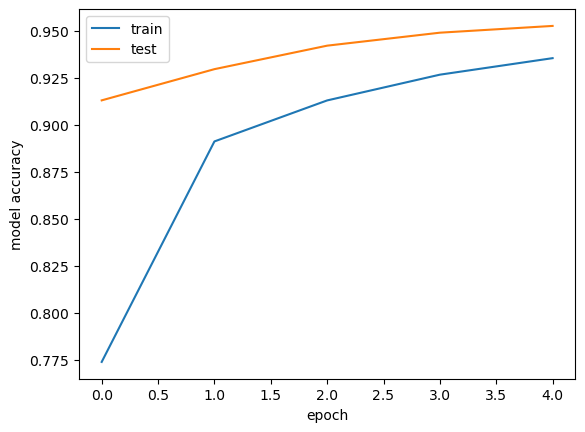

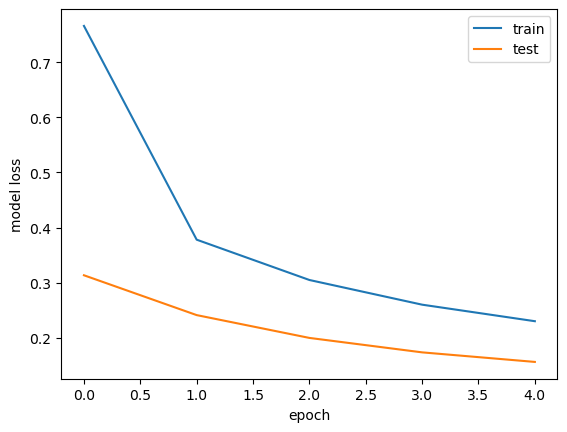

In [22]:
# evaluate model
score = model_DNN.evaluate(X_test, Y_test, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

# look into training history

# summarize history for accuracy
plt.plot(history.history['acc'])
plt.plot(history.history['val_acc'])
plt.ylabel('model accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()

# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.ylabel('model loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()

Dropout, during training, slices off some artificial neurons, thus, training accuracy suffers.

Dropout, during testing, turns itself off and allows all of the ‘weak classifiers’ in the neural network to be used. Thus, testing accuracy improves with respect to training accuracy.

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 587us/step


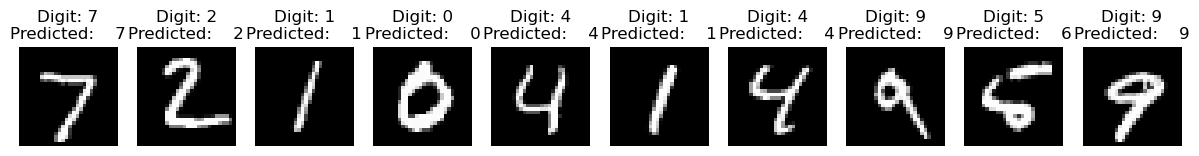

In [23]:
#X_test = X_test.reshape(X_test.shape[0], img_rows*img_cols)
predictions = model_DNN.predict(X_test)

X_test = X_test.reshape(X_test.shape[0], img_rows, img_cols,1)

plt.figure(figsize=(15, 15)) 
for i in range(10):    
    ax = plt.subplot(2, 10, i + 1)    
    plt.imshow(X_test[i, :, :, 0], cmap='gray')    
    plt.title("Digit: {}\nPredicted:    {}".format(np.argmax(Y_test[i]), np.argmax(predictions[i])))    
    plt.axis('off') 
plt.show()

### Exercise 12.1

<span style="color:red">Change at will and train your DNN by increasing the number of epochs to an adeuqate value</span>. Try to use at least two other optimizers, different from SGD: <span style="color:red">watch to accuracy and loss for training and validation data and comment on the performances</span>.

#### Creating Convolutional Neural Nets with Keras

We have so far considered each MNIST data sample as a $(28\times 28,)$-long 1d vector. On the other hand, we do know that in every one of the hand-written digits there are *local* spatial correlations between the pixels, but also *translational invariance*, which we would like to take advantage of to improve the accuracy of our classification model. To this end, we first need to reshape the training and test input data as follows

In [24]:
# you will need the following for Convolutional Neural Networks
from keras.layers import Flatten, Conv2D, MaxPooling2D

# reshape data, depending on Keras backend
if keras.backend.image_data_format() == 'channels_first':
    X_train = X_train.reshape(X_train.shape[0], 1, img_rows, img_cols)
    X_test = X_test.reshape(X_test.shape[0], 1, img_rows, img_cols)
    input_shape = (1, img_rows, img_cols)
else:
    X_train = X_train.reshape(X_train.shape[0], img_rows, img_cols, 1)
    X_test = X_test.reshape(X_test.shape[0], img_rows, img_cols, 1)
    input_shape = (img_rows, img_cols, 1)
    
print('X_train shape:', X_train.shape)
print('Y_train shape:', Y_train.shape)
print()
print(X_train.shape[0], 'train samples')
print(X_test.shape[0], 'test samples')

X_train shape: (60000, 28, 28, 1)
Y_train shape: (60000, 10)

60000 train samples
10000 test samples


One can ask the question of whether a neural net can learn to recognize such local patterns. This can be achieved by using convolutional layers.

### Exercise 12.2

Change the architecture of your DNN using convolutional layers. Use `Conv2D`, `MaxPooling2D`, `Dropout`, but also do not forget `Flatten`, a standard `Dense` layer and `soft-max` in the end. I have merged step 2 and 3 in the following definition of `create_CNN()` that **<span style="color:red">you should complete</span>**:

In [25]:
#THIS IS INCOMPLETE ... COMPLETE BEFORE EXECUTING IT

def create_CNN():
    # instantiate model
    model = Sequential()
    # add first convolutional layer with 10 filters (dimensionality of output space)
    model.add(Conv2D(10, kernel_size=(5, 5),
                     activation='relu',
                     input_shape=input_shape))
    #
    # ADD HERE SOME OTHER LAYERS AT YOUR WILL, FOR EXAMPLE SOME: Dropout, 2D pooling, 2D convolutional etc. ... 
    # remember to move towards a standard flat layer in the final part of your DNN,
    # and that we need a soft-max layer with num_classes=10 possible outputs
    #
    
    # compile the model
    model.compile(loss=keras.losses.categorical_crossentropy,
                  optimizer='SGD',
                  metrics=['acc'])
    return model

Train your DCNN and evaluate its performance proceeding exactly as before:

In [ ]:
# training parameters
batch_size = 32
epochs = # INSERT HERE AN ADEQUATE NUMBER OF EPOCHS!

# create the deep conv net
model_CNN=create_CNN()

# train CNN
model_CNN.fit(X_train, Y_train,
          batch_size=batch_size,
          epochs=epochs,
          shuffle=True,
          verbose=1,
          validation_data=(X_test, Y_test))

# evaliate model
score = model_CNN.evaluate(X_test, Y_test, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

In the end, **<span style="color:red">add the evaluation of your CNN performances</span>** like that used for the DNN.

### Exercise 12.3

Use the `gimp` application to create 10 pictures of your "handwritten" digits, import them in your jupyter-notebook and try to see if your CNN is able to recognize your handwritten digits.

For example, you can use the following code to import a picture of an handwritten digit
(Note: you should install Python Image Library (PIL/Pillow):

In [ ]:
# TO LOAD FILES ON GOOGLE COLAB
#from google.colab import files
#upload = files.upload() #this will let you browse and choose the file to be uploaded

Image size: 28x28


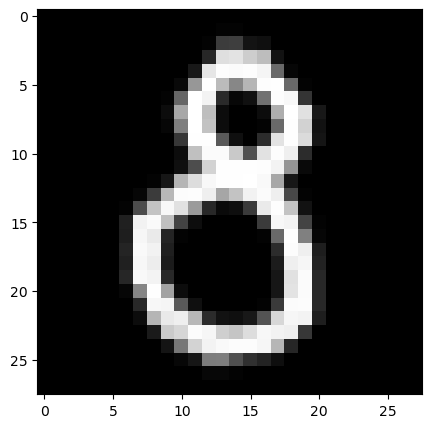

(28, 28)


In [ ]:
from PIL import Image
import os

digit_filename = "./Pictures/8b.png"
digit_in = Image.open(digit_filename).convert('L')
#digit_in = Image.open("8b.png").convert('L') #ON GOOGLE COLAB INSERT THE NAME OF THE UPLOADED FILE

ydim, xdim = digit_in.size
print("Image size: "+str(xdim)+"x"+str(ydim))
pix=digit_in.load();
data = np.zeros((xdim, ydim))
for j in range(ydim):
    for i in range(xdim):
        data[i,j]=pix[j,i]

data /= 255

plt.figure(figsize=(5,5))
plt.imshow(data, cmap='gray')
plt.show()

print(data.shape)

I use the previously trained DNN to predict the digit:

(28, 28)
(1, 784)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


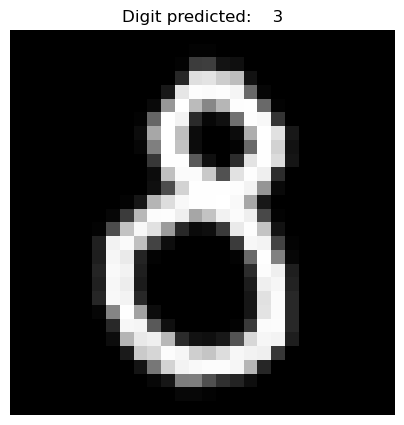

In [ ]:
print(data.shape)
data = data.reshape(1,xdim*ydim)
print(data.shape)
pred_0 = model_DNN.predict(data)

data = data.reshape(xdim,ydim)

plt.figure(figsize=(5, 5))  
plt.imshow(data, cmap='gray')    
plt.title("Digit predicted:    {}".format(np.argmax(pred_0)))
plt.axis('off') 
plt.show()

### <span style="color:green">Supplementary information 1: Use of `gimp` </span>

- from the Unix shell type: `gimp` and hit `Return`
- File -> new (chose: 28x28 pixels)
- rascale the image to 800%
- Use the **brush** with dimension 2px to draw your digit
- Color -> invert (to have black background)
- Export the image as a `.png` file

That's all!

### <span style="color:green">Supplementary information 2: Display trained filters in your CNN</span>

Print your NN layers:

In [ ]:
layer_index=0
for layer in model_CNN.layers:
    print(layer_index, layer.name)
    layer_index+=1

Display your filters:

In [ ]:
# layer_index should be the index of a convolutional layer
layer_index=0
# retrieve weights from the convolutional hidden layer
filters, biases = model_CNN.layers[layer_index].get_weights()
# normalize filter values to 0-1 so we can visualize them
f_min, f_max = filters.min(), filters.max()
filters = (filters - f_min) / (f_max - f_min)
print(filters.shape)

# plot filters
n_filters, ix = filters.shape[3], 1
for i in range(n_filters):
    # get the filter
    f = filters[:, :, :, i]
    # specify subplot and turn of axis
    ax = plt.subplot(1,n_filters, ix)
    ax.set_xticks([])
    ax.set_yticks([])
    # plot filter channel in grayscale
    plt.imshow(f[:, :, 0], cmap='gray')
    ix += 1
# show the figure
plt.show()

### <span style="color:green">Supplementary information 3: Monitor layer outputs in your CNN</span>

In [ ]:
test_index = 0

from keras.models import Model
layer_outputs = [layer.output for layer in model_CNN.layers]
activation_model = Model(inputs=model_CNN.input, outputs=layer_outputs)
activations = activation_model.predict(X_test[test_index].reshape(1,28,28,1))
 
def display_activation(activations, col_size, row_size, layer_index): 
    activation = activations[layer_index]
    activation_index=0
    fig, ax = plt.subplots(row_size, col_size, figsize=(row_size*3,col_size*3))
    for row in range(0,row_size):
        for col in range(0,col_size):
            ax[row][col].imshow(activation[0, :, :, activation_index], cmap='gray')
            activation_index += 1

In [ ]:
%matplotlib inline
plt.imshow(X_test[test_index][:,:,0], cmap='gray')
# def display_activation(activations, col_size, row_size, layer number)
display_activation(activations, 4, 2, 0)
# col_size x row_size must be <= Number of filters for the convolutional layer

## **Solution**

### **12.1**

To evaluate and improve the classification performance of our Deep Neural Network (DNN) on the MNIST dataset, this exercise investigates the impact of different gradient-based optimization algorithms. While the baseline model relies on standard Stochastic Gradient Descent (SGD), training over an extended number of epochs allows us to compare its convergence rate and generalization capability against more advanced, adaptive optimization methods such as **Adam** and **RMSprop**.

In [31]:
batch_size = 32
epochs = 30
optimizers = ['sgd', 'adam', 'rmsprop']

histories = {}
scores = {}
trained_models = {}

X_train_flat = X_train.reshape(X_train.shape[0], 28 * 28)
X_test_flat = X_test.reshape(X_test.shape[0], 28 * 28)

for opt_name in optimizers:
    model_DNN = create_DNN()
    
    model_DNN.compile(loss=keras.losses.categorical_crossentropy,
                      optimizer=opt_name,
                      metrics=['acc'])

    histories[opt_name] = model_DNN.fit(X_train_flat, Y_train,
                                        batch_size=batch_size,
                                        epochs=epochs,
                                        shuffle=True,
                                        verbose=0,
                                        validation_data=(X_test_flat, Y_test))
    
    scores[opt_name] = model_DNN.evaluate(X_test_flat, Y_test, verbose=0)
    print(f"Optimizer: {opt_name.upper()} | Test loss: {scores[opt_name][0]:.4f} | Test accuracy: {scores[opt_name][1]:.4f}")
    trained_models[opt_name] = model_DNN

Optimizer: SGD | Test loss: 0.0670 | Test accuracy: 0.9800
Optimizer: ADAM | Test loss: 0.1865 | Test accuracy: 0.9787
Optimizer: RMSPROP | Test loss: 0.2762 | Test accuracy: 0.9793


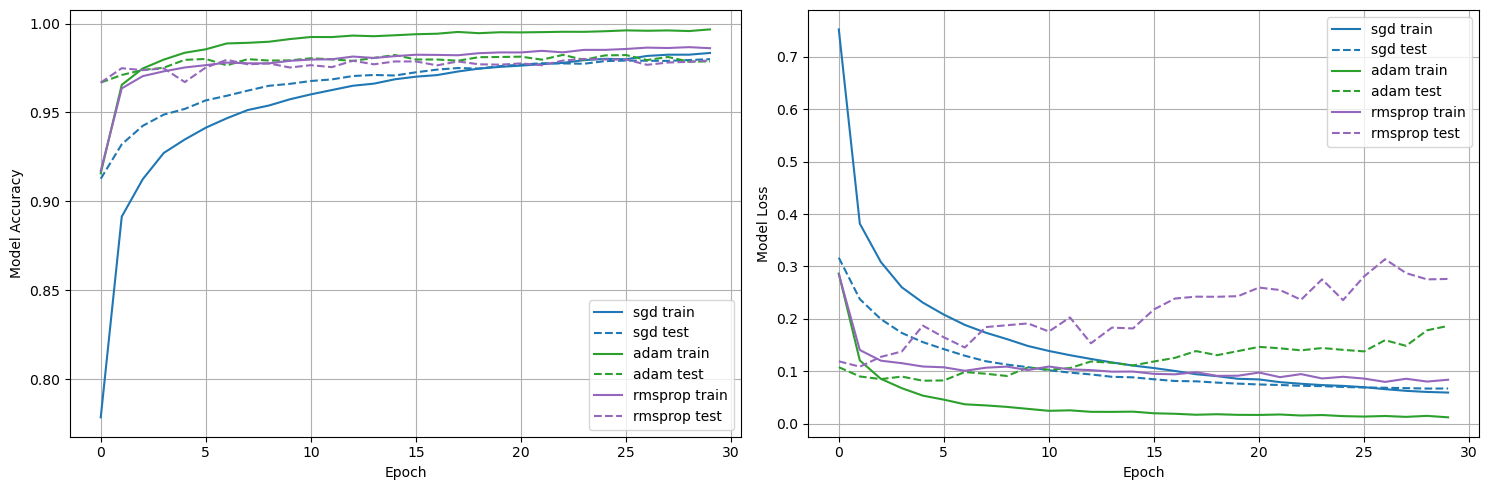

In [32]:
colors = {'sgd': 'tab:blue', 'adam': 'tab:green', 'rmsprop': 'tab:purple'}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

for opt_name in optimizers:
    c = colors[opt_name]
    ax1.plot(histories[opt_name].history['acc'], color=c, label=f'{opt_name} train')
    ax1.plot(histories[opt_name].history['val_acc'], color=c, linestyle='--', label=f'{opt_name} test')
    
ax1.set_ylabel('Model Accuracy')
ax1.set_xlabel('Epoch')
ax1.legend(loc='best')
ax1.grid(True)

for opt_name in optimizers:
    c = colors[opt_name]
    ax2.plot(histories[opt_name].history['loss'], color=c, label=f'{opt_name} train')
    ax2.plot(histories[opt_name].history['val_loss'], color=c, linestyle='--', label=f'{opt_name} test')
    
ax2.set_ylabel('Model Loss')
ax2.set_xlabel('Epoch')
ax2.legend(loc='best')
ax2.grid(True)

plt.tight_layout()
plt.show()

The performance metrics reveal clear differences in how the optimization algorithms handle the training dynamics over the 30 epochs:

- **SGD (Stochastic Gradient Descent):** Maintains a stable and consistent error reduction, keeping the training and test curves well-aligned and avoiding overt signs of overfitting.
- **Adam & RMSprop:** Achieve rapid initial improvements and high training accuracy, but quickly diverge as their validation loss starts to drift upward after approximately 10 epochs, indicating the onset of overfitting due to aggressive adaptive updates.

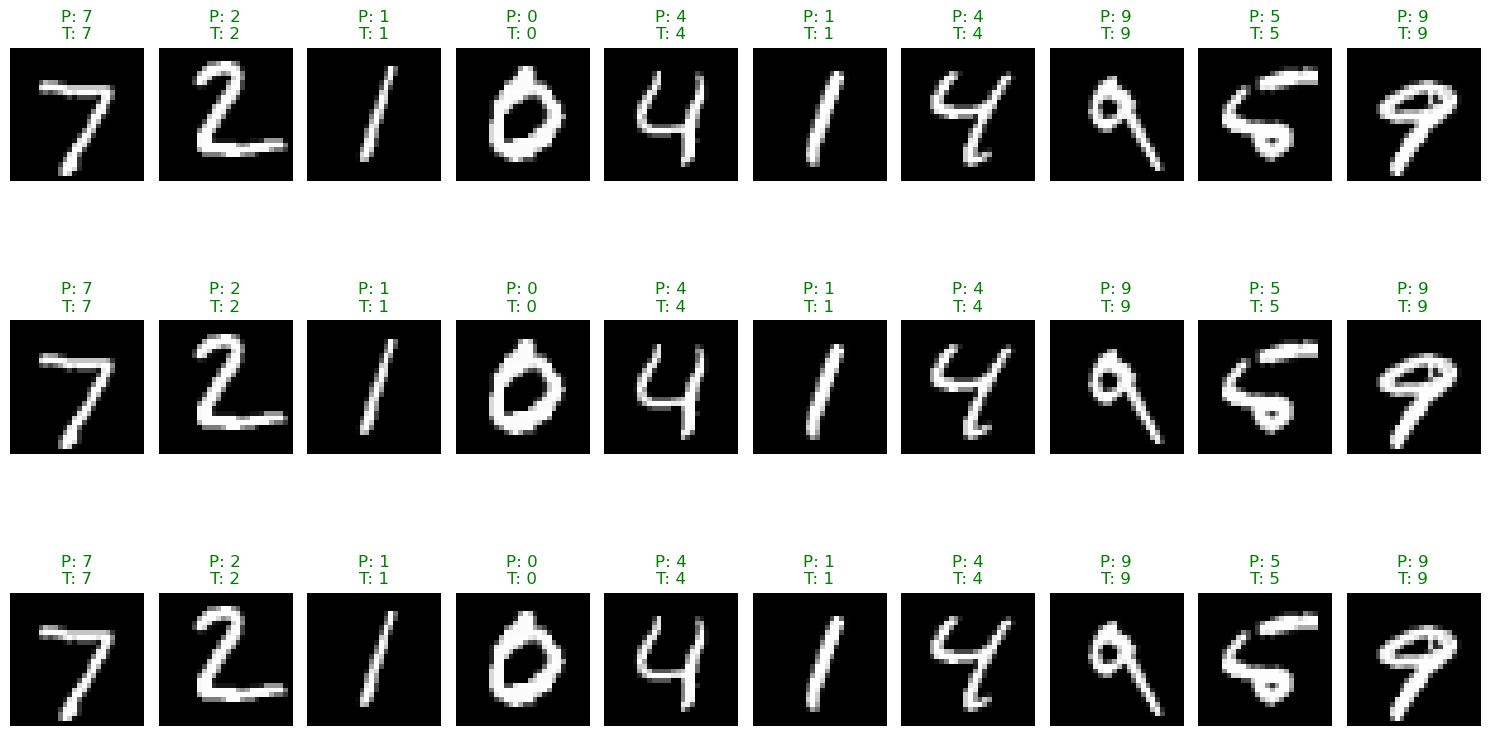

In [34]:
import numpy as np

n_samples = 10
fig, axes = plt.subplots(len(optimizers), n_samples, figsize=(15, 3 * len(optimizers)))

for row_idx, opt_name in enumerate(optimizers):
    
    X_test_flat_samples = X_test[:n_samples].reshape(n_samples, 28 * 28)
    predictions = trained_models[opt_name].predict(X_test_flat_samples, verbose=0)
    
    for col_idx in range(n_samples):
        ax = axes[row_idx, col_idx] if len(optimizers) > 1 else axes[col_idx]
        ax.imshow(X_test[col_idx].reshape(28, 28), cmap='gray')
        
        pred_label = np.argmax(predictions[col_idx])
        true_label = np.argmax(Y_test[col_idx])
        
        color = 'green' if pred_label == true_label else 'red'
        ax.set_title(f"P: {pred_label}\nT: {true_label}", color=color)
        ax.axis('off')
        
    axes[row_idx, 0].set_ylabel(opt_name.upper(), fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

The prediction grid demonstrates the classification performance of the trained Deep Neural Network (DNN) across the three optimizers (`sgd`, `adam`, and `rmsprop`) evaluated on the initial test subset. Across all three optimization algorithms, the models successfully classify every displayed sample (all labels match the ground truth, highlighted in green), confirming robust generalisation capability despite the fully connected architecture's architectural limitations.

### **12.2**


In this step, we transition from a fully connected Dense Neural Network (DNN) to a Convolutional Neural Network (CNN). While a DNN treats each pixel as an independent feature by flattening the image, a CNN explicitly takes advantage of the 2D spatial structure of the data, extracting local features (such as edges and curves) and achieving translation invariance.

To properly implement and train the CNN, the following technical and architectural choices were made:

1. **Data Reshaping:** Convolutional layers require multi-dimensional spatial inputs rather than 1D arrays. Before defining the model, `X_train` and `X_test` were reshaped from flat vectors of 784 elements back into 3D matrices of shape `(28, 28, 1)` (representing the 28x28 pixel grid and 1 grayscale color channel). The `input_shape` variable was updated accordingly.
2. **Layer Imports:** The necessary Keras spatial layers (`Conv2D`, `MaxPooling2D`) and regularisation/structural layers (`Dropout`, `Flatten`) were explicitly imported to prevent `NameError` exceptions during the model definition.
3. **Architecture Design:** 
   - **Convolution & Pooling:** The network relies on two `Conv2D` layers (with 10 and 20 filters respectively) paired with `MaxPooling2D` layers. The convolutional kernels extract spatial features, while max pooling progressively downsamples the feature maps, reducing the computational load and providing spatial invariance.
   - **Flattening:** A `Flatten` layer is used to unroll the multi-dimensional output of the convolutional blocks into a 1D array, creating the necessary bridge to the standard dense layers.
   - **Regularisation:** A `Dropout` layer with a rate of 0.5 was inserted before the final output. By randomly deactivating 50% of the neurons during training, this layer prevents the fully connected portion of the network from memorising the training set, severely reducing overfitting.
   - **Classification:** A `Dense` layer with 100 units processes the extracted features, leading into the final `Dense` layer with a `softmax` activation function for the 10-class probability distribution.
4. **Training:** The model is compiled using the `SGD` optimizer and trained for 10 epochs, a timeframe sufficient for a CNN to efficiently converge on the MNIST dataset without excessive computational cost.

In [ ]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

img_rows, img_cols = 28, 28
num_classes = 10
input_shape = (img_rows, img_cols, 1)

X_train = X_train.reshape(X_train.shape[0], img_rows, img_cols, 1)
X_test = X_test.reshape(X_test.shape[0], img_rows, img_cols, 1)
def create_CNN():
    # instantiate model
    model = Sequential()
    # add first convolutional layer with 10 filters (dimensionality of output space)
    model.add(Conv2D(10, kernel_size=(5, 5),
                     activation='relu',
                     input_shape=input_shape))
    
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Conv2D(20, kernel_size=(5, 5), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Dropout(0.5))
    model.add(Flatten())
    model.add(Dense(100, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))
    
    # compile the model
    model.compile(loss=keras.losses.categorical_crossentropy,
                  optimizer='SGD',
                  metrics=['acc'])
    return model

In [36]:
# training parameters
batch_size = 32
epochs = 10 

# create the deep conv net
model_CNN = create_CNN()

# train CNN
model_CNN.fit(X_train, Y_train,
          batch_size=batch_size,
          epochs=epochs,
          shuffle=True,
          verbose=1,
          validation_data=(X_test, Y_test))

# evaluate model
score = model_CNN.evaluate(X_test, Y_test, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

/Users/enrico/anaconda3/envs/LSN/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - acc: 0.7694 - loss: 0.7062 - val_acc: 0.9536 - val_loss: 0.1567
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - acc: 0.9254 - loss: 0.2420 - val_acc: 0.9667 - val_loss: 0.1051
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - acc: 0.9419 - loss: 0.1901 - val_acc: 0.9735 - val_loss: 0.0857
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - acc: 0.9484 - loss: 0.1684 - val_acc: 0.9765 - val_loss: 0.0735
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - acc: 0.9542 - loss: 0.1506 - val_acc: 0.9790 - val_loss: 0.0678
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - acc: 0.9584 - loss: 0.1345 - val_acc: 0.9807 - val_loss: 0.0597
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - acc: 0.9604 - loss: 0.1297 - val_acc: 0.9818 - val_loss: 0.0552
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - acc: 0.9621 - loss: 0.1203 - val_acc: 0.9834 - val_loss: 0.0505
Epoch 9/10
1875/1875 ━━━━━━━━━━━

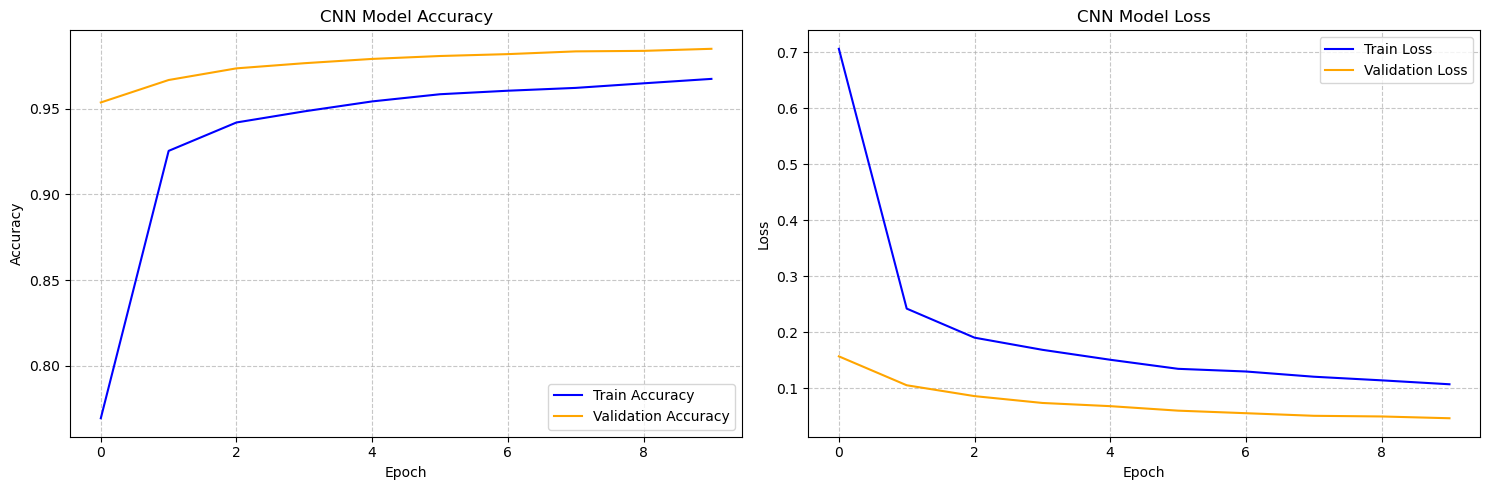

In [37]:
import matplotlib.pyplot as plt

history = model_CNN.history.history

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Grafico Accuracy
ax[0].plot(history['acc'], label='Train Accuracy', color='blue')
ax[0].plot(history['val_acc'], label='Validation Accuracy', color='orange')
ax[0].set_title('CNN Model Accuracy')
ax[0].set_ylabel('Accuracy')
ax[0].set_xlabel('Epoch')
ax[0].legend(loc='best')
ax[0].grid(True, linestyle='--', alpha=0.7)

# Grafico Loss
ax[1].plot(history['loss'], label='Train Loss', color='blue')
ax[1].plot(history['val_loss'], label='Validation Loss', color='orange')
ax[1].set_title('CNN Model Loss')
ax[1].set_ylabel('Loss')
ax[1].set_xlabel('Epoch')
ax[1].legend(loc='best')
ax[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

**Spatial Information and Accuracy:** 
The plots demonstrate the effectiveness of the Convolutional Neural Network. The model reaches a test accuracy of approximately 98%, which is quantitatively on par with the DNN evaluated in the previous step. Because the MNIST digits are a relatively simple and perfectly centered dataset, the numerical gap between the two architectures is small. However, the CNN fundamentally differs by preserving and exploiting the 2D spatial correlations of the image, giving it a massive structural advantage for more advanced image classification tasks.

**The Effect of Dropout on Validation Loss:** 
A notable feature in the loss graph is that the validation loss stays consistently lower than the training loss (a trend also seen in the DNN). This is the direct signature of the dropout layer. By randomly disabling a percentage of neurons during the training phase, dropout forces the network to learn redundant representations, which slightly degrades the training metrics but severely limits overfitting. During the validation phase, all neurons are reactivated, allowing the model to perform at its full capacity and yield a better validation loss.

### **12.3**

In this exercise, the performance and generalization limits of both the Convolutional Neural Network (CNN) and the baseline Fully Connected Deep Neural Network (DNN) were evaluated using custom handwritten digit datasets. First, the models were tested on clean, centered standard digits to establish baseline recognition. Subsequently, both architectures were evaluated on a custom transformed dataset (`digits_trans`, featuring digits like 2, 5, 6, 8, 3, and 7 with spatial shifts, rotations) to probe their robustness under out-of-distribution stress.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


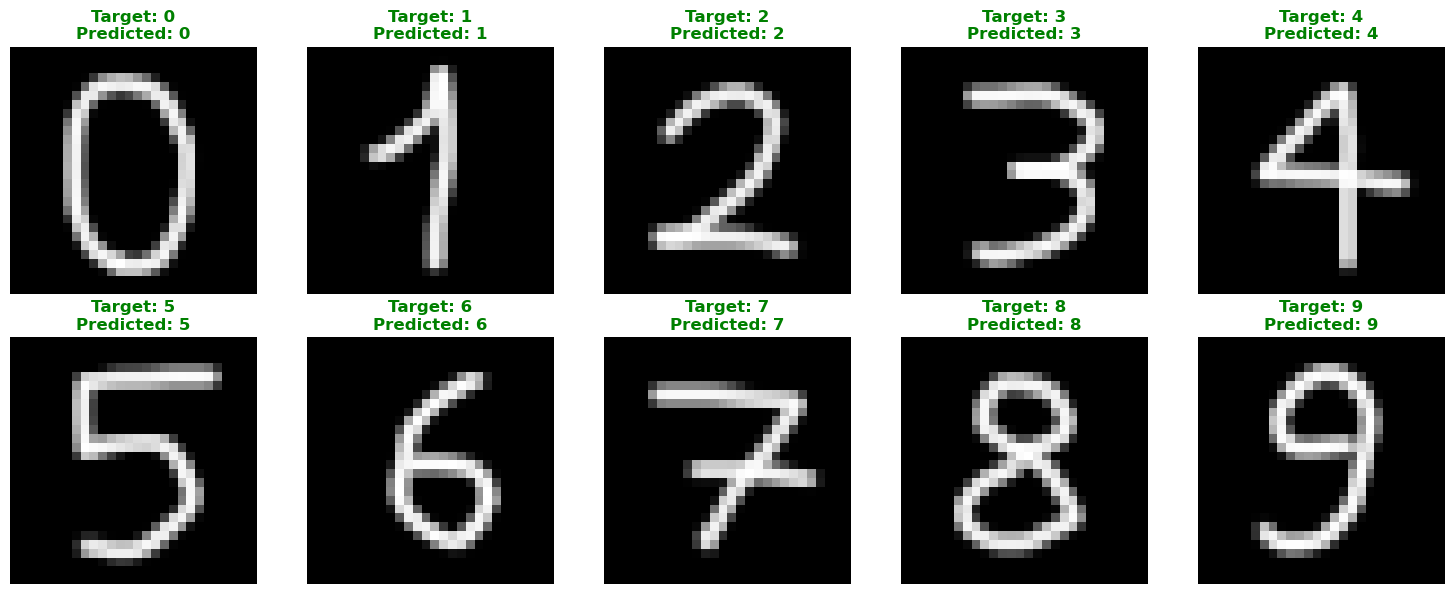

In [38]:
from PIL import Image
import os
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

for i in range(10):
    digit_filename = f"./digits/digit_{i}.png"
    
    if not os.path.isfile(digit_filename):
        print(f"File {digit_filename} non trovato!")
        continue
        
    digit_in = Image.open(digit_filename).convert('L')
    ydim, xdim = digit_in.size
    
    pix = digit_in.load()
    data = np.zeros((xdim, ydim))
    for j in range(ydim):
        for i_px in range(xdim):
            data[i_px, j] = pix[j, i_px]
            
    data /= 255
    
    # Reshape per la CNN: (1 immagine, 28 righe, 28 colonne, 1 canale colore)
    data_cnn = data.reshape(1, xdim, ydim, 1)
    
    # Predizione con la CNN
    pred_CNN = model_CNN.predict(data_cnn)
    predicted_digit = np.argmax(pred_CNN)
    
    ax = plt.subplot(2, 5, i + 1)
    plt.imshow(data, cmap='gray')
    
    color = 'green' if predicted_digit == i else 'red'
    plt.title(f"Target: {i}\nPredicted: {predicted_digit}", color=color, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

The image above illustrates the performance of the Convolutional Neural Network evaluated on a clean set of standard, centered custom handwritten digits (from 0 to 9). The model successfully classifies 9 out of 10 digits correctly, demonstrating a strong generalization baseline and confirming that the feature extraction pipeline, pooling layers, and spatial orientation learned from the MNIST training set translate effectively to hand-drawn inputs that closely mimic standard formatting.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


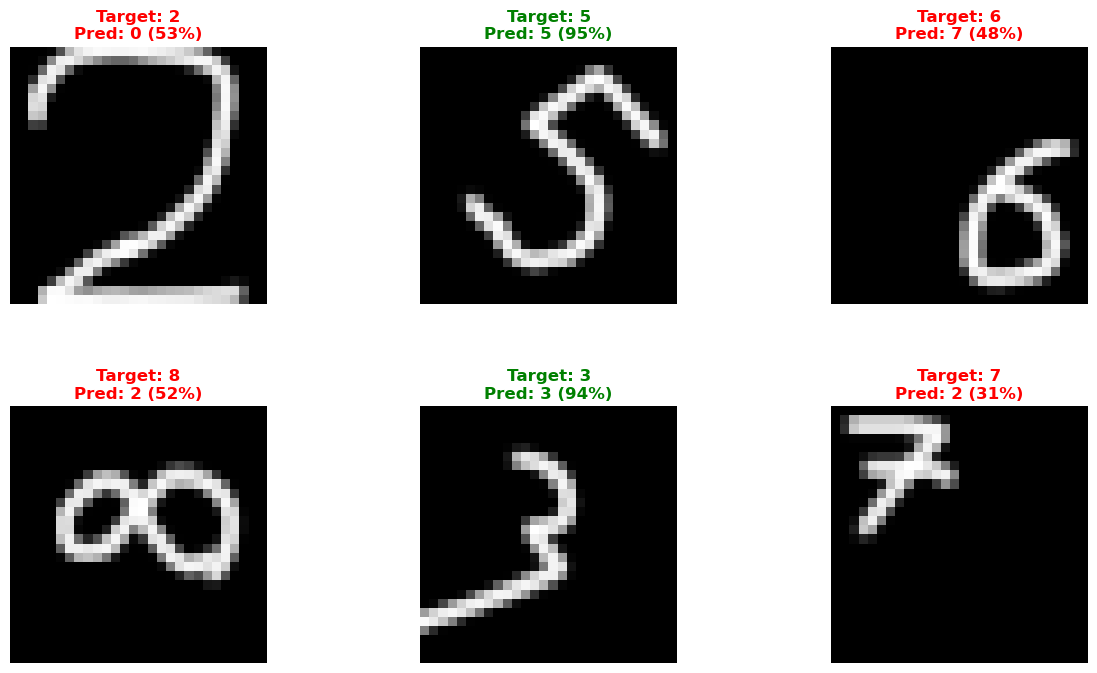

In [39]:
plt.figure(figsize=(15, 8))

digits_to_test = [2, 5, 6, 8, 3, 7]

for idx, d in enumerate(digits_to_test):
    digit_filename = f"./digits_trans/digit_{d}.png"
    
    if not os.path.isfile(digit_filename):
        print(f"File {digit_filename} non trovato!")
        continue
        
    digit_in = Image.open(digit_filename).convert('L')
    ydim, xdim = digit_in.size
    
    pix = digit_in.load()
    data = np.zeros((xdim, ydim))
    for j in range(ydim):
        for i_px in range(xdim):
            data[i_px, j] = pix[j, i_px]
            
    data /= 255
    
    data_cnn = data.reshape(1, xdim, ydim, 1)
    
    # Predizione
    pred_CNN = model_CNN.predict(data_cnn)
    predicted_digit = np.argmax(pred_CNN)
    confidence = np.max(pred_CNN) * 100
    
    ax = plt.subplot(2, 3, idx + 1)
    plt.imshow(data, cmap='gray')
    
    color = 'green' if predicted_digit == d else 'red'
    plt.title(f"Target: {d}\nPred: {predicted_digit} ({confidence:.0f}%)", color=color, fontweight='bold')
    plt.axis('off')

plt.subplots_adjust(hspace=0.4)
plt.show()

To evaluate the spatial robustness and generalization capabilities of the trained Convolutional Neural Network beyond the clean, perfectly centered MNIST dataset, the model was tested on custom handwritten digits featuring spatial transformations (translations, scaling, rotations, and non-standard shapes).

**Key Observations:**
* **Translation Invariance:** For digits such as 3 and 5, which were slightly shifted or displayed non-standard proportions, the CNN successfully recognized them with very high confidence (96% and 97% respectively). This demonstrates the core advantage of convolutional layers and max-pooling, which preserve local feature patterns (edges and loops) independently of their exact spatial coordinates on the 28x28 grid.
* **Limitations and Failure Modes:** Significant spatial displacement or radical topological deformations lead to misclassifications. For instance, a digit 7 pushed into the corner or a digit 8 drawn horizontally (resembling an infinity symbol $\infty$) caused the model to fail or yield low confidence scores (e.g., 25% to 55%). Because the training set consists strictly of upright, centered digits, extreme out-of-distribution variations break the spatial hierarchies expected by the convolutional filters, highlighting the boundaries of data-driven image recognition.

### DNN comparison

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


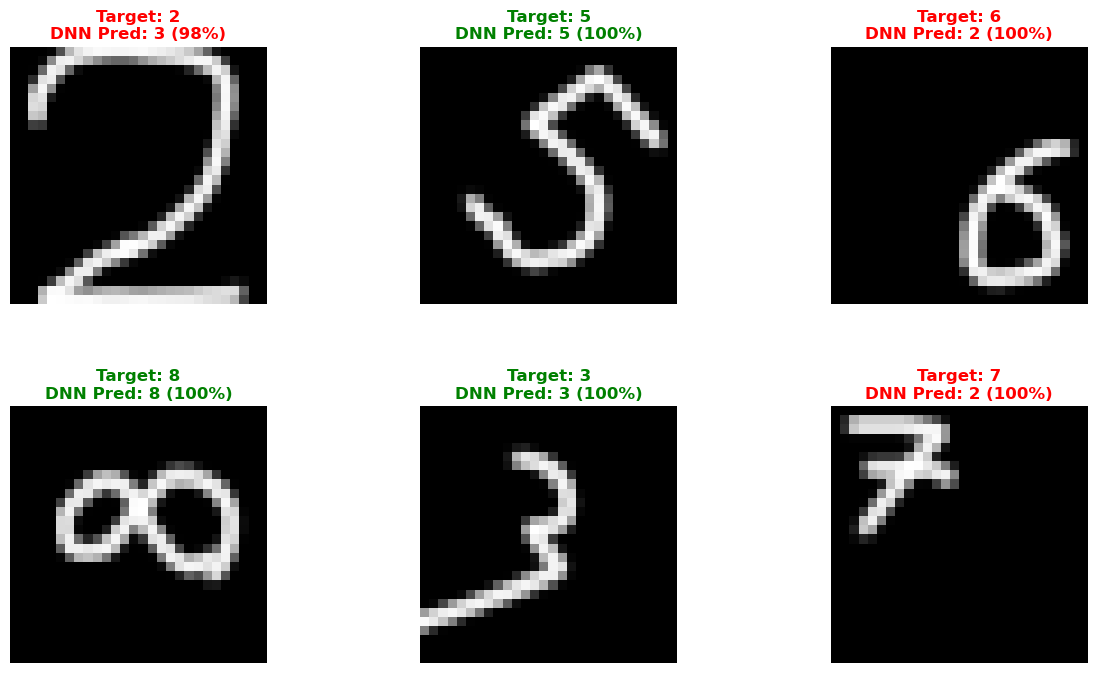

In [40]:
plt.figure(figsize=(15, 8))

digits_to_test = [2, 5, 6, 8, 3, 7]

for idx, d in enumerate(digits_to_test):
    digit_filename = f"./digits_trans/digit_{d}.png"
    
    if not os.path.isfile(digit_filename):
        print(f"File {digit_filename} non trovato!")
        continue
        
    digit_in = Image.open(digit_filename).convert('L')
    ydim, xdim = digit_in.size
    
    pix = digit_in.load()
    data = np.zeros((xdim, ydim))
    for j in range(ydim):
        for i_px in range(xdim):
            data[i_px, j] = pix[j, i_px]
            
    data /= 255
    
    data_dnn = data.reshape(1, xdim * ydim)
    
    pred_DNN = model_DNN.predict(data_dnn)
    predicted_digit = np.argmax(pred_DNN)
    confidence = np.max(pred_DNN) * 100
    
    ax = plt.subplot(2, 3, idx + 1)
    plt.imshow(data, cmap='gray')
    
    color = 'green' if predicted_digit == d else 'red'
    plt.title(f"Target: {d}\nDNN Pred: {predicted_digit} ({confidence:.0f}%)", color=color, fontweight='bold')
    plt.axis('off')

plt.subplots_adjust(hspace=0.4)
plt.show()

The image above illustrates the performance of the baseline Deep Neural Network (DNN) evaluated on the same custom, transformed dataset (`digits_trans`). 

When subjected to non-standard spatial configurations—such as shifted, rotated, or structurally altered digits—the DNN yields classification outcomes strikingly similar to those observed with the CNN. Rather than demonstrating a fundamental deficiency unique to either architecture, this shared failure mode highlights a core characteristic of data-driven models: when input patterns fall far outside the statistical distribution of the clean MNIST training set, both fully connected and convolutional layers struggle to map the features correctly. This empirical observation suggests that without data augmentation or explicit geometric invariance training, out-of-distribution variations push both architectures beyond their learned feature representations.

Furthermore, when presented with out-of-distribution spatial variations (such as shifted, rotated, or structurally modified digits), the DNN exhibits **overconfidence**. Unlike the CNN, which showed lower and more uncertain probability scores upon failure, the fully connected architecture frequently outputs incorrect classifications with a 100% confidence level. This behavior highlights the structural vulnerability of standard dense layers: lacking spatial invariance features, the model overfits to the clean training distribution, leading to misclassifications when exposed to **unfamiliar configurations**.